In [2]:
import pandas as pd
import re
import nltk

In [3]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)


In [5]:
df = pd.read_csv("twitter.csv")
df["tweet"] = df["tweet"].astype(str)
df["label"] = df["label"].astype(int)

In [6]:
nltk.download("stopwords")
nltk.download("wordnet")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tejas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\tejas\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [7]:

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


In [8]:
def clean_text(text):
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+|#\w+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = text.lower().split()
    text = [lemmatizer.lemmatize(w) for w in text if w not in stop_words]
    return " ".join(text)

In [9]:
df["clean_text"] = df["tweet"].apply(clean_text)

In [10]:
X = df["clean_text"]
y = df["label"]

In [11]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
tfidf_baseline = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9,
    stop_words="english",
    sublinear_tf=True
)

In [13]:

X_train_base = tfidf_baseline.fit_transform(X_train_text)
X_test_base  = tfidf_baseline.transform(X_test_text)


In [14]:
baseline_model = LogisticRegression(max_iter=2000, class_weight="balanced")
baseline_model.fit(X_train_base, y_train)
pred_base = baseline_model.predict(X_test_base)


In [15]:
tfidf = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9,
    stop_words="english",
    sublinear_tf=True
)

In [16]:

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf  = tfidf.transform(X_test_text)


In [17]:

selector = SelectKBest(score_func=chi2, k=5000)
X_train_sel = selector.fit_transform(X_train_tfidf, y_train)
X_test_sel  = selector.transform(X_test_tfidf)

In [18]:
proposed_model = LinearSVC(class_weight="balanced")
proposed_model.fit(X_train_sel, y_train)
pred_prop = proposed_model.predict(X_test_sel)

In [19]:

print("TF-IDF (train) feature count:", X_train_tfidf.shape[1])
print("After Chi-Square selected features:", X_train_sel.shape[1])

TF-IDF (train) feature count: 16972
After Chi-Square selected features: 5000


In [20]:
def report(name, y_true, y_pred):
    print(f"\n===== {name} =====")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision(weighted):", precision_score(y_true, y_pred, average="weighted"))
    print("Recall(weighted)   :", recall_score(y_true, y_pred, average="weighted"))
    print("F1(weighted)       :", f1_score(y_true, y_pred, average="weighted"))
    print("\nClassification Report (0=Normal, 1=Hate/Offensive):\n")
    print(classification_report(y_true, y_pred, target_names=["Normal (0)", "Hate/Offensive (1)"]))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

In [21]:

report("Baseline: Hybrid TF-IDF", y_test, pred_base)
report("Proposed: TF-IDF + Chi-Square", y_test, pred_prop)


===== Baseline: Hybrid TF-IDF =====
Accuracy : 0.9116220866572814
Precision(weighted): 0.9372247944227328
Recall(weighted)   : 0.9116220866572814
F1(weighted)       : 0.9214430387553696

Classification Report (0=Normal, 1=Hate/Offensive):

                    precision    recall  f1-score   support

        Normal (0)       0.98      0.93      0.95      5945
Hate/Offensive (1)       0.42      0.70      0.53       448

          accuracy                           0.91      6393
         macro avg       0.70      0.81      0.74      6393
      weighted avg       0.94      0.91      0.92      6393

Confusion Matrix:
 [[5515  430]
 [ 135  313]]

===== Proposed: TF-IDF + Chi-Square =====
Accuracy : 0.9247614578445175
Precision(weighted): 0.9382888921072668
Recall(weighted)   : 0.9247614578445175
F1(weighted)       : 0.9302940720403559

Classification Report (0=Normal, 1=Hate/Offensive):

                    precision    recall  f1-score   support

        Normal (0)       0.97      0.94   

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "acc": "accuracy",
    "f1w": "f1_weighted",
    "precw": "precision_weighted",
    "recw": "recall_weighted",
}

In [23]:
baseline_cv = cross_validate(baseline_model, X_train_base, y_train, cv=cv, scoring=scoring)
proposed_cv = cross_validate(proposed_model, X_train_sel, y_train, cv=cv, scoring=scoring)

In [24]:
print("\n===== 5-Fold CV Results (Train set only) =====")
print("Baseline CV Accuracy mean:", baseline_cv["test_acc"].mean())
print("Baseline CV F1(weighted) mean:", baseline_cv["test_f1w"].mean())


===== 5-Fold CV Results (Train set only) =====
Baseline CV Accuracy mean: 0.9188081084349393
Baseline CV F1(weighted) mean: 0.9260288927634115


In [25]:
            
print("Proposed CV Accuracy mean:", proposed_cv["test_acc"].mean())
print("Proposed CV F1(weighted) mean:", proposed_cv["test_f1w"].mean())

Proposed CV Accuracy mean: 0.9308147711543139
Proposed CV F1(weighted) mean: 0.9337540253302133


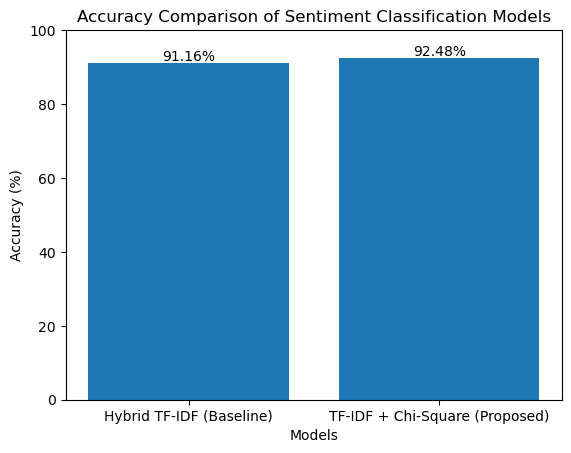

In [26]:
import matplotlib.pyplot as plt

# Data
models = ["Hybrid TF-IDF (Baseline)", "TF-IDF + Chi-Square (Proposed)"]
accuracies = [91.16, 92.48]

# Create bar graph
plt.figure()
plt.bar(models, accuracies)

# Labels and title
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of Sentiment Classification Models")
plt.ylim(0, 100)

# Add value labels
for i in range(len(models)):
    plt.text(i, accuracies[i] + 0.5, f"{accuracies[i]}%", ha='center')

plt.show()


In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_prop)
print(cm)


[[5618  327]
 [ 154  294]]


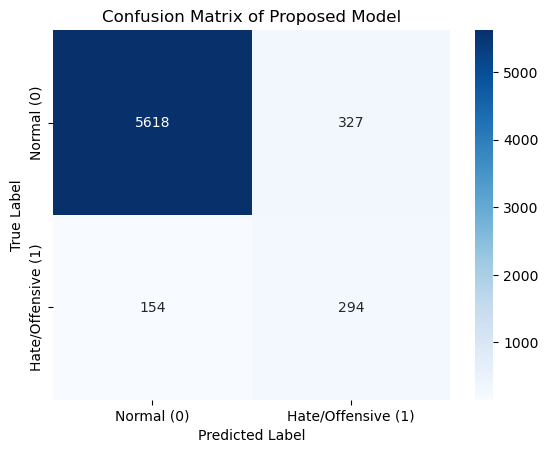

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate predictions again (safe)
pred_prop = proposed_model.predict(X_test_sel)

# Compute confusion matrix
cm = confusion_matrix(y_test, pred_prop)

# Plot
plt.figure()
sns.heatmap(cm, 
            annot=True, 
            fmt="d", 
            cmap="Blues",   # Same pleasant blue gradient
            xticklabels=["Normal (0)", "Hate/Offensive (1)"],
            yticklabels=["Normal (0)", "Hate/Offensive (1)"])

plt.title("Confusion Matrix of Proposed Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()
